# Portfolio Construction: Mean-Variance, Black–Litterman, HRP, CVaR

Every allocation method looks good in sample. What an investment or treasury committee needs to know is how a method behaves when its inputs are estimated, re-estimated every month and traded at a cost. This notebook runs seven methods through the same walk-forward test and shows what each one holds today and where its risk comes from.

**What it does.** It builds a 12-ETF multi-asset portfolio with seven allocation methods and runs them all through the same walk-forward backtest, re-optimised monthly from January 2010, net of transaction costs. It then shows what each method holds today and where its risk comes from.

**Data.** Daily total-return prices of 12 U.S.-listed ETFs since 2007 covering U.S. and international equity, Treasuries, TIPS, credit, real estate, gold and commodities (Yahoo Finance), and the 3-month T-bill (FRED) as the risk-free rate.

**Methods.** 1/N, minimum variance and mean-variance (max Sharpe) on a Ledoit–Wolf covariance, Black–Litterman with momentum views, equal risk contribution, hierarchical risk parity (López de Prado, 2016), and minimum CVaR by linear programming (Rockafellar–Uryasev) in cvxpy. All are long-only with a 35% cap.

**Key output.** Out-of-sample return, volatility, Sharpe ratio, drawdown, CVaR and turnover by method, cumulative wealth, current weights and risk contributions, and an allocation dashboard.

## 1. Why compare allocation methods out of sample

Every optimiser looks good in sample. The real question for an investment or treasury committee is how a method behaves with **estimated** inputs, re-estimated every month, after trading costs. The methods differ mainly in how much they trust each estimate:

| Method | Uses expected returns? | Uses covariances? | Known weakness |
|---|---|---|---|
| **1/N** | no | no | ignores risk entirely |
| **Minimum variance** | no | yes | concentrates in low-vol assets |
| **Mean-variance (max Sharpe)** | yes (sample means) | yes | "error maximisation" (Michaud): extreme weights from noisy means |
| **Black–Litterman** | blended: equilibrium + views | yes | depends on views and confidence |
| **Equal risk contribution** | no | yes | levers into bonds when unconstrained |
| **HRP** | no | yes, via a clustering tree | heuristic; ignores some correlations by design |
| **Minimum CVaR** | no | full empirical distribution | needs many scenarios; sensitive to the window |

For an MDB treasury this is the choice between a liquidity portfolio optimised for return and one optimised for **robustness**: low drawdowns and stable weights.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import cvxpy as cp
import yfinance as yf
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

TICKERS = [
    "SPY",
    "IWM",
    "EFA",
    "EEM",
    "TLT",
    "IEF",
    "TIP",
    "LQD",
    "HYG",
    "VNQ",
    "GLD",
    "DBC",
]
ASSET_CLASS = {
    "SPY": "US equity",
    "IWM": "US equity",
    "EFA": "Intl equity",
    "EEM": "Intl equity",
    "TLT": "Treasuries",
    "IEF": "Treasuries",
    "TIP": "Inflation-linked",
    "LQD": "Credit",
    "HYG": "Credit",
    "VNQ": "Real estate",
    "GLD": "Commodities",
    "DBC": "Commodities",
}
START = "2007-05-01"
BACKTEST_START = "2010-01-01"
# 3 years of daily returns for risk estimates
LOOKBACK_DAYS = 756
W_MAX = 0.35
# one-way transaction cost per unit of turnover
COST_BP = 10
RISK_AVERSION = 2.5  # Black–Litterman equilibrium δ
TAU = 0.05
# Reference "market" weights for the Black–Litterman prior: a global
# 60/40-style policy portfolio
W_MKT = {
    "SPY": 0.30,
    "IWM": 0.05,
    "EFA": 0.15,
    "EEM": 0.05,
    "TLT": 0.08,
    "IEF": 0.12,
    "TIP": 0.05,
    "LQD": 0.08,
    "HYG": 0.04,
    "VNQ": 0.03,
    "GLD": 0.03,
    "DBC": 0.02,
}

print(
    f"cvxpy {cp.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

cvxpy 1.9.3 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


STRAT_COLORS = {
    "1/N": "#9c9b97",
    "Min variance": PALETTE[0],
    "Mean-variance": PALETTE[7],
    "Black-Litterman": PALETTE[3],
    "Risk parity (ERC)": PALETTE[2],
    "HRP": PALETTE[6],
    "Min CVaR": PALETTE[1],
}

## 3. Data

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ]
    if isinstance(px, pd.Series):
        px = px.to_frame(TICKERS[0])
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px[TICKERS].reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
# completed sessions only (no intraday row)
prices = prices[prices.index < pd.Timestamp.today().normalize()]
prices = prices.dropna(how="all").ffill(limit=3)

# --- Data cleaning: one-day bad prints that reverse the next day are replaced
# by interpolation
raw_ret = np.log(prices).diff()
# robust daily sigma
scale = raw_ret.abs().rolling(120, min_periods=40).median().shift() / 0.6745
spike = (raw_ret.abs() > 10 * scale) & (
    (raw_ret + raw_ret.shift(-1)).abs() < 0.25 * raw_ret.abs()
)
# A genuine crash-and-rebound (e.g. 12-13 Mar 2020) moves many assets at once;
# a bad print is idiosyncratic.
market_wide = (raw_ret.abs() > 4 * scale).sum(axis=1) >= 3
spike = (
    spike & ~market_wide.values[:, None]
    if prices.shape[1] >= 3
    else spike & False
)
for c in prices.columns[spike.any()]:
    print(
        f"Data fix · {c}: bad print on"
        f" {', '.join(f'{d:%Y-%m-%d}' for d in spike.index[spike[c]])} interpolated"
    )
prices = prices.mask(spike).interpolate(limit_area="inside")
returns = np.log(prices).diff().dropna()
EVAL_DATE = returns.index.max()
print(
    f"{len(returns):,} trading days · {returns.index.min():%Y-%m-%d} →"
    f" {EVAL_DATE:%Y-%m-%d} · {', '.join(prices.columns)}"
)

4,897 trading days · 2007-05-02 → 2026-10-16 · SPY, IWM, EFA, EEM, TLT, IEF, TIP, LQD, HYG, VNQ, GLD, DBC


In [4]:
rf_daily = fred.get_series("DTB3", observation_start=START).dropna() / 100
rf_daily = rf_daily.reindex(returns.index).ffill().bfill() / 252
simple = np.expm1(returns)
month_ends = simple.resample("ME").last().index
rebal_dates = [
    d
    for d in simple.index.to_series()
    .groupby(simple.index.to_period("M"))
    .max()
    if d >= pd.Timestamp(BACKTEST_START)
]
print(
    f"{len(rebal_dates)} monthly rebalancing dates from {rebal_dates[0]:%b %Y}"
)
(simple.mean() * 252 * 100).round(1).to_frame("ann. mean return %").join(
    (simple.std() * np.sqrt(252) * 100).round(1).rename("ann. vol %")
).T

202 monthly rebalancing dates from Jan 2010


,SPY,IWM,EFA,EEM,TLT,IEF,TIP,LQD,HYG,VNQ,GLD,DBC
ann. mean return %,12.20,10.60,6.70,8.20,3.70,3.20,3.40,4.10,5.20,9.30,10.60,4.40
ann. vol %,19.60,24.70,21.60,28.00,15.10,7.00,6.30,8.80,10.80,29.50,18.20,19.30


## 4. The seven allocators

Every allocator sees only the last three years of daily returns at each rebalancing date. The covariance is shrunk with Ledoit–Wolf, which stabilises all covariance-based methods. Constraints are identical: fully invested, long-only, at most 35% in one ETF.

In [5]:
N = len(TICKERS)
w_mkt = np.array([W_MKT[t] for t in TICKERS])


def solve_qp(objective, extra=()):
    w = cp.Variable(N)
    cons = [cp.sum(w) == 1, w >= 0, w <= W_MAX, *[c(w) for c in extra]]
    cp.Problem(objective(w), cons).solve(solver=cp.CLARABEL)
    return np.clip(w.value, 0, None) / np.clip(w.value, 0, None).sum()


def min_variance(R, S):
    return solve_qp(lambda w: cp.Minimize(cp.quad_form(w, cp.psd_wrap(S))))


def max_sharpe(mu, S):
    """
    Max Sharpe via the standard homogenisation: minimise y'Sy s.t. mu'y = 1,
    then rescale.
    """
    if np.max(mu) <= 0:
        return min_variance(None, S)
    y, k = cp.Variable(N), cp.Variable()
    cons = [mu @ y == 1, y >= 0, y <= W_MAX * k, cp.sum(y) == k, k >= 0]
    cp.Problem(cp.Minimize(cp.quad_form(y, cp.psd_wrap(S))), cons).solve(
        solver=cp.CLARABEL
    )
    w = np.clip(y.value / k.value, 0, None)
    return w / w.sum()


def black_litterman(R, S):
    """
    Equilibrium returns from the policy weights, plus one relative momentum
    view: top-4 beat bottom-4 by their spread.
    """
    pi = RISK_AVERSION * S @ w_mkt
    # 12-1 month momentum
    mom = (1 + R.iloc[-252:-21]).prod().values - 1
    order = np.argsort(mom)
    P = np.zeros((1, N))
    P[0, order[-4:]], P[0, order[:4]] = 0.25, -0.25
    # half the realised spread, annual
    Q = np.array([0.5 * (mom[order[-4:]].mean() - mom[order[:4]].mean())])
    Omega = TAU * P @ S @ P.T
    tS = TAU * S
    post = np.linalg.solve(
        np.linalg.inv(tS) + P.T @ np.linalg.inv(Omega) @ P,
        np.linalg.inv(tS) @ pi + P.T @ np.linalg.inv(Omega) @ Q,
    )
    return max_sharpe(
        post,
        S + np.linalg.inv(np.linalg.inv(tS) + P.T @ np.linalg.inv(Omega) @ P),
    )


def risk_parity(R, S):
    """
    Equal risk contribution via the convex log-barrier formulation (Spinu
    2013), then capped.
    """
    y = cp.Variable(N)
    cp.Problem(
        cp.Minimize(
            0.5 * cp.quad_form(y, cp.psd_wrap(S)) - cp.sum(cp.log(y)) / N
        ),
        [y >= 1e-8],
    ).solve(solver=cp.CLARABEL)
    w = y.value / y.value.sum()
    # cap, redistributing pro rata
    if w.max() > W_MAX:
        for _ in range(20):
            excess = np.clip(w - W_MAX, 0, None).sum()
            w = np.minimum(w, W_MAX)
            free = w < W_MAX
            w[free] += excess * w[free] / w[free].sum()
    return w


def hrp(R, S):
    cov = S
    sd = np.sqrt(np.diag(cov))
    corr = cov / np.outer(sd, sd)
    dist = np.sqrt(np.clip(0.5 * (1 - corr), 0, None))
    order = leaves_list(
        linkage(squareform(dist, checks=False), method="single")
    )
    w = np.ones(N)
    clusters = [list(order)]
    while clusters:
        nxt = []
        for c in clusters:
            if len(c) < 2:
                continue
            a, b = c[: len(c) // 2], c[len(c) // 2 :]

            def ivp_var(idx):
                sub = cov[np.ix_(idx, idx)]
                iv = 1 / np.diag(sub)
                iv /= iv.sum()
                return iv @ sub @ iv

            va, vb = ivp_var(a), ivp_var(b)
            alpha = 1 - va / (va + vb)
            w[a] *= alpha
            w[b] *= 1 - alpha
            nxt += [a, b]
        clusters = nxt
    w = w / w.sum()
    # same 35% cap as the others
    for _ in range(20):
        excess = np.clip(w - W_MAX, 0, None).sum()
        if excess < 1e-10:
            break
        w = np.minimum(w, W_MAX)
        free = w < W_MAX
        w[free] += excess * w[free] / w[free].sum()
    return w


def min_cvar(R, S, alpha=0.95):
    X = R.values
    T_, _ = X.shape
    w, var, u = cp.Variable(N), cp.Variable(), cp.Variable(T_)
    loss = -X @ w
    cons = [cp.sum(w) == 1, w >= 0, w <= W_MAX, u >= 0, u >= loss - var]
    cp.Problem(cp.Minimize(var + cp.sum(u) / ((1 - alpha) * T_)), cons).solve(
        solver=cp.HIGHS
    )
    return np.clip(w.value, 0, None) / np.clip(w.value, 0, None).sum()


ALLOCATORS = {
    "1/N": lambda R, S: np.full(N, 1 / N),
    "Min variance": min_variance,
    "Mean-variance": lambda R, S: max_sharpe(R.mean().values * 252, S),
    "Black-Litterman": black_litterman,
    "Risk parity (ERC)": risk_parity,
    "HRP": hrp,
    "Min CVaR": min_cvar,
}

## 5. Walk-forward backtest, 2010–2026

At each month-end, every allocator gets the trailing three years and returns new weights. The portfolio then drifts with daily returns until the next rebalance. Turnover is charged at 10 bp one-way. Performance is measured on daily net returns.

In [6]:
weights_hist = {s: {} for s in ALLOCATORS}
t0 = time.perf_counter()
for d in rebal_dates:
    hist = simple.loc[:d].iloc[-LOOKBACK_DAYS:]
    S_ann = LedoitWolf().fit(hist.values).covariance_ * 252
    for name, fn in ALLOCATORS.items():
        weights_hist[name][d] = fn(hist, S_ann)
print(
    f"{len(rebal_dates) * len(ALLOCATORS):,} optimisations in"
    f" {time.perf_counter() - t0:.0f}s"
)


def backtest(wh):
    dates = sorted(wh)
    w = np.zeros(N)
    out, turn = [], []
    days = simple.loc[dates[0] :].index
    rebal_set = set(dates)
    for day in days[1:]:
        r = simple.loc[day].values
        gross = w @ r
        w = w * (1 + r) / (1 + gross) if w.sum() > 0 else w
        cost = 0.0
        if day in rebal_set or (day == days[1]):
            target = wh[max(d for d in dates if d <= day)]
            tr = np.abs(target - w).sum()
            cost = tr * COST_BP / 1e4
            turn.append(tr)
            w = target.copy()
        out.append(gross - cost)
    return pd.Series(out, index=days[1:]), np.array(turn)


perf, turnovers = {}, {}
for name in ALLOCATORS:
    perf[name], turnovers[name] = backtest(weights_hist[name])
perf = pd.DataFrame(perf)
rf = rf_daily.reindex(perf.index).fillna(0)


def stats_of(r, name):
    wealth = (1 + r).cumprod()
    dd = wealth / wealth.cummax() - 1
    m = (1 + r).resample("ME").prod() - 1
    years = len(r) / 252
    ann = wealth.iloc[-1] ** (1 / years) - 1
    vol = r.std() * np.sqrt(252)
    W = pd.DataFrame(weights_hist[name]).T
    return {
        "ann. return %": ann * 100,
        "ann. vol %": vol * 100,
        "Sharpe": (r - rf).mean() / r.std() * np.sqrt(252),
        "max drawdown %": dd.min() * 100,
        "monthly CVaR95 %": -m[m <= m.quantile(0.05)].mean() * 100,
        "worst year %": (1 + r).resample("YE").prod().sub(1).min() * 100,
        "annual turnover ×": turnovers[name].sum() / years,
        "avg effective assets": (1 / (W**2).sum(axis=1)).mean(),
        "avg max weight %": W.max(axis=1).mean() * 100,
    }


scoreboard = pd.DataFrame({n: stats_of(perf[n], n) for n in ALLOCATORS}).T
scoreboard.round(2)

1,414 optimisations in 9s


,ann. return %,ann. vol %,Sharpe,max drawdown %,monthly CVaR95 %,worst year %,annual turnover ×,avg effective assets,avg max weight %
1/N,6.67,9.15,0.59,-20.77,5.13,-14.27,0.34,12.00,8.33
Min variance,3.95,4.82,0.52,-14.65,3.02,-11.64,0.42,3.53,34.89
Mean-variance,6.55,7.62,0.67,-18.35,4.07,-14.17,2.28,3.81,34.61
Black-Litterman,6.91,11.59,0.51,-21.63,5.89,-12.79,5.35,4.22,33.61
Risk parity (ERC),5.45,6.54,0.61,-19.16,3.98,-14.01,0.33,9.05,18.98
HRP,4.40,5.62,0.53,-17.50,3.46,-13.08,0.59,5.27,32.02
Min CVaR,3.90,4.89,0.50,-15.90,3.08,-12.64,0.65,3.50,34.96


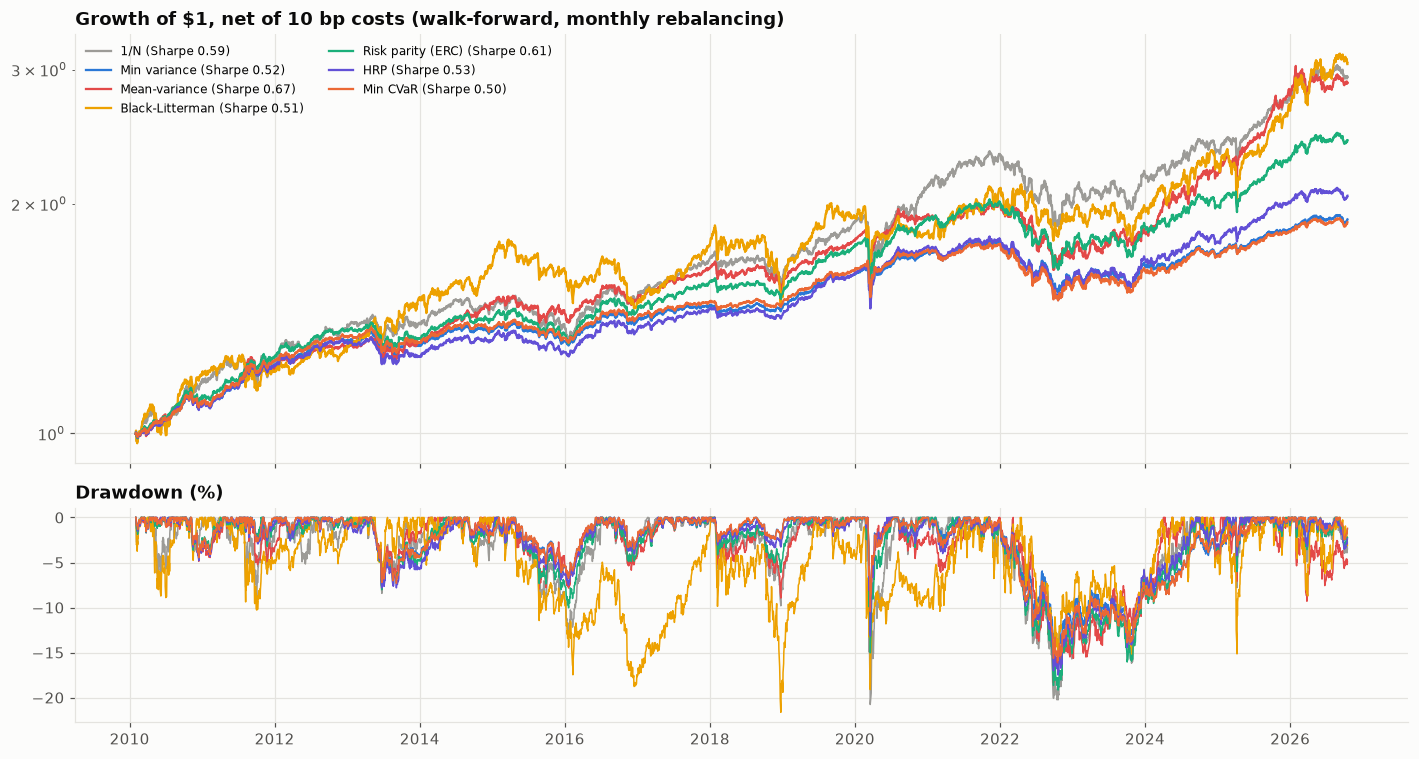

In [7]:
# --- Chart 1: cumulative wealth and drawdowns
wealth = (1 + perf).cumprod()
fig, axes = plt.subplots(
    2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)
for name, color in STRAT_COLORS.items():
    axes[0].plot(
        wealth.index,
        wealth[name],
        color=color,
        lw=1.5,
        label=f"{name} (Sharpe {scoreboard.loc[name, 'Sharpe']:.2f})",
    )
    axes[1].plot(
        wealth.index,
        (wealth[name] / wealth[name].cummax() - 1) * 100,
        color=color,
        lw=1,
    )
axes[0].set_yscale("log")
axes[0].set_title(
    "Growth of $1, net of 10 bp costs (walk-forward, monthly rebalancing)"
)
axes[0].legend(fontsize=8, ncol=2)
axes[1].set_title("Drawdown (%)")
plt.tight_layout()
save_fig(fig, "01_wealth_and_drawdowns")
plt.show()

## 6. Today's portfolios and where their risk comes from

The risk contribution of asset $i$ is $w_i(\Sigma w)_i/\sigma_p$. Its share shows which assets actually drive the portfolio's volatility, which can be very different from the capital weights.

In [8]:
last = rebal_dates[-1]
hist = simple.loc[:last].iloc[-LOOKBACK_DAYS:]
S_now = LedoitWolf().fit(hist.values).covariance_ * 252
W_now = pd.DataFrame(
    {n: weights_hist[n][last] for n in ALLOCATORS}, index=TICKERS
)
RC_now = W_now.apply(lambda w: w * (S_now @ w) / (w @ S_now @ w))
by_class_w = W_now.groupby(ASSET_CLASS).sum() * 100
by_class_rc = RC_now.groupby(ASSET_CLASS).sum() * 100

dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.14,
    horizontal_spacing=0.08,
    specs=[[{"colspan": 2}, None], [{}, {}]],
    subplot_titles=(
        "Growth of $1 (log scale), net of costs",
        f"Weights by asset class, {last:%d %b %Y} (%)",
        "Risk contribution by asset class (%)",
    ),
)
for name, color in STRAT_COLORS.items():
    dash.add_trace(
        go.Scatter(
            x=wealth.index,
            y=wealth[name],
            name=name,
            line=dict(color=color, width=1.6),
        ),
        1,
        1,
    )
CLASS_COLORS = dict(zip(sorted(set(ASSET_CLASS.values())), PALETTE))
for cls in by_class_w.index:
    dash.add_trace(
        go.Bar(
            x=list(ALLOCATORS),
            y=by_class_w.loc[cls],
            name=cls,
            marker_color=CLASS_COLORS[cls],
            legendgroup=cls,
            showlegend=True,
        ),
        2,
        1,
    )
    dash.add_trace(
        go.Bar(
            x=list(ALLOCATORS),
            y=by_class_rc.loc[cls],
            name=cls,
            marker_color=CLASS_COLORS[cls],
            legendgroup=cls,
            showlegend=False,
        ),
        2,
        2,
    )
best = scoreboard["Sharpe"].idxmax()
dash.update_layout(
    height=900,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    barmode="stack",
    font=dict(color=INK_2),
    legend=dict(orientation="h", y=-0.08),
    margin=dict(t=120),
    title=dict(
        x=0.01,
        text=(
            "<b>Multi-asset allocation · walk-forward"
            f" {rebal_dates[0]:%Y}–{last:%Y}</b><br>"
            f"<span style='font-size:13px;color:{INK_2}'>12 ETFs · 7 methods ·"
            f" monthly, 10 bp costs · best Sharpe: {best} "
            f"({scoreboard.loc[best, 'Sharpe']:.2f}) · smallest drawdown:"
            f" {scoreboard['max drawdown %'].idxmax()} "
            f"({scoreboard['max drawdown %'].max():.1f}%)</span>"
        ),
    ),
)
dash.update_yaxes(type="log", row=1, col=1)
save_dashboard(dash, "dashboard")
scoreboard.to_csv(OUT_DIR / "backtest_scoreboard.csv")
W_now.to_csv(OUT_DIR / "current_weights.csv")
pd.concat({
    n: pd.DataFrame(weights_hist[n]).T.set_axis(TICKERS, axis=1)
    for n in ALLOCATORS
}).to_csv(OUT_DIR / "weights_history.csv")
dash.show()
(W_now * 100).round(1)

Dashboard saved: outputs/dashboard.html and .png


,1/N,Min variance,Mean-variance,Black-Litterman,Risk parity (ERC),HRP,Min CVaR
SPY,8.30,0.00,17.00,35.00,5.40,2.30,0.00
IWM,8.30,0.00,0.00,0.00,3.70,1.70,0.00
EFA,8.30,0.00,0.00,18.40,4.80,1.90,0.00
EEM,8.30,0.00,0.00,21.90,4.20,1.10,0.00
TLT,8.30,0.00,0.00,0.00,6.80,2.90,0.00
IEF,8.30,21.10,0.00,0.00,13.90,11.50,18.80
TIP,8.30,35.00,21.00,0.00,17.20,33.60,35.00
LQD,8.30,0.00,0.00,0.00,10.10,14.70,0.00
HYG,8.30,35.00,35.00,0.00,13.00,18.50,35.00
VNQ,8.30,0.00,0.00,0.00,4.90,4.40,0.00


## 7. Reading the results and limitations

Walk-forward January 2010 to October 2026, net of 10 bp costs:

**No method dominates.** Mean-variance has the best Sharpe ratio (0.67), Black–Litterman the highest return (6.9% a year), and minimum variance the smallest drawdown (−14.7%) and worst year (−11.6%). The return-free methods (minimum variance, minimum CVaR, HRP) cluster at 4–4.5% return and 5–6% volatility, with Sharpe ratios of 0.50–0.53, the same as **1/N** (0.59) within noise. That is DeMiguel et al.'s "1/N is hard to beat" result, reproduced.

- **Mean-variance did not blow up**, because the 35% cap and Ledoit–Wolf shrinkage tame the error-maximisation problem. It still holds only about 4 effective assets and turns over 2.3× a year, against 0.3× for 1/N and ERC.
- **Black–Litterman with a momentum view** has the most volatile path (11.6% vol) and by far the highest turnover (5.4× a year), because the view flips with momentum. The prior anchors the weights but does not stop them from chasing the view.
- **Risk parity is the most diversified risk-based method** (9 effective assets, max weight 19%). HRP gets a smaller drawdown than ERC but piles into TIPS and investment-grade credit today (33% TIPS). Its tree treats those low-vol, highly correlated bond ETFs as a cluster that deserves a large share of the budget.
- **Weights vs risk today:** minimum variance and minimum CVaR hold 35% TIPS and 35% high yield, so credit (HYG) is a third of their risk. Mean-variance's 14% in commodities (DBC) and 13% in gold carry about half its risk. Capital weights alone would hide both.
- **For an MDB liquidity portfolio,** the relevant frontier is drawdown and turnover, not Sharpe: minimum variance, minimum CVaR and HRP deliver drawdowns of 15–18% with turnover under 0.7× a year, and their risk contributions are what a treasury risk limit should be written on.

**Limitations**

- One sample (2010–2026), in which U.S. equities dominated and bonds suffered their worst drawdown in decades in 2022. Rankings are sample-dependent, and a block bootstrap of the backtest would show how much.
- ETF proxies, no taxes, a flat 10 bp cost. The policy weights in the Black–Litterman prior are an assumption, not true market caps.
- A single 3-year window and a 35% cap for all methods. Both choices matter as much as the method itself, especially for mean-variance and minimum CVaR.

## References

### Finance and regulation

- Markowitz, H. (1952). Portfolio selection. *The Journal of Finance, 7*(1), 77–91. https://doi.org/10.1111/j.1540-6261.1952.tb01525.x
- Black, F., & Litterman, R. (1992). Global portfolio optimization. *Financial Analysts Journal, 48*(5), 28–43. https://doi.org/10.2469/faj.v48.n5.28
- López de Prado, M. (2016). Building diversified portfolios that outperform out of sample. *The Journal of Portfolio Management, 42*(4), 59–69. https://doi.org/10.3905/jpm.2016.42.4.059
- Maillard, S., Roncalli, T., & Teïletche, J. (2010). The properties of equally weighted risk contribution portfolios. *The Journal of Portfolio Management, 36*(4), 60–70. https://doi.org/10.3905/jpm.2010.36.4.060
- Rockafellar, R. T., & Uryasev, S. (2000). Optimization of conditional value-at-risk. *Journal of Risk, 2*(3), 21–41. https://doi.org/10.21314/JOR.2000.038
- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal versus naive diversification: How inefficient is the 1/N portfolio strategy? *The Review of Financial Studies, 22*(5), 1915–1953. https://doi.org/10.1093/rfs/hhm075
- Ledoit, O., & Wolf, M. (2004). Honey, I shrunk the sample covariance matrix. *The Journal of Portfolio Management, 30*(4), 110–119. https://doi.org/10.3905/jpm.2004.110

### Machine learning and deep learning

- Diamond, S., & Boyd, S. (2016). CVXPY: A Python-embedded modeling language for convex optimization. *Journal of Machine Learning Research, 17*(83), 1–5. https://jmlr.org/papers/v17/15-408.html
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845